# Демонстрация библиотеки `advanced_experiments` на `smoking.csv`

Этот ноутбук — практический walkthrough по основным возможностям библиотеки.

Что в итоге получим:
- подготовленные панельные данные,
- подбор контрольной группы,
- Synthetic Control и визуализации эффекта,
- conformal inference,
- пакетный `Experiment`,
- placebo-анализ для проверки устойчивости эффекта.


## 1. Импорты и окружение

Что делаем:
- подключаем все публичные API библиотеки,
- включаем `autoreload`, чтобы изменения в `.py` подхватывались без перезапуска.

Зачем:
- ускорить итерации и сделать код ноутбука воспроизводимым.


In [8]:
%load_ext autoreload
%autoreload 2


from pathlib import Path
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

sys.path.append("/Users/zugzvangg/Desktop/Projects/advanced_experiments/")

from cib_advanced_experiments import (
    DifferenceInDifferences,
    Experiment,
    SyntheticControl,
    build_conformal_frame,
    prepare_panel_data,
    prepare_rdd_data,
    propensity_score_match,
    select_control_group_by_features,
    select_control_group_by_propensity_from_panel,
)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Загружаем `smoking.csv`

Что делаем:
- читаем датасет и проверяем базовые характеристики.

Зачем:
- убедиться, что структура данных корректна до начала каузального анализа.


In [9]:
raw = pd.read_csv("data/smoking.csv")
raw.head()

,state,year,cigsale,lnincome,beer,age15to24,retprice,california,after_treatment
0,1,1970,89.800003,NaN,NaN,0.178862,39.599998,False,False
1,1,1971,95.400002,NaN,NaN,0.179928,42.700001,False,False
2,1,1972,101.099998,9.498476,NaN,0.180994,42.299999,False,False
3,1,1973,102.900002,9.550107,NaN,0.182060,42.099998,False,False
4,1,1974,108.199997,9.537163,NaN,0.183126,43.099998,False,False


### Быстрая sanity-check после загрузки

Что делаем:
- выводим размер, список колонок, диапазон лет.

Зачем:
- быстро убедиться, что читаем тот датасет и в нужном формате.


In [10]:
print("shape:", raw.shape)
print("columns:", raw.columns.tolist())
print("treated state:", raw.loc[raw["california"] == True, "state"].unique())
print("year range:", raw["year"].min(), "-", raw["year"].max())

shape: (1209, 9)
columns: ['state', 'year', 'cigsale', 'lnincome', 'beer', 'age15to24', 'retprice', 'california', 'after_treatment']
treated state: [3]
year range: 1970 - 2000


## 3. Подготовка данных

Что делаем:
- приводим колонки к рабочему формату (`state` как id, `date` как datetime),
- выделяем treated-unit и дату интервенции,
- собираем список control units.

Зачем:
- все последующие API ожидают единый формат panel-data.


### Приводим данные к рабочему виду

Что делаем:
- создаём рабочий `df`, формируем datetime-ось, выделяем treated и control.

Зачем:
- единый формат нужен для всех API библиотеки.


In [11]:
df = raw.copy()
df["state"] = df["state"].astype(str)
df["date"] = pd.to_datetime(df["year"].astype(str) + "-01-01")

treated_state = df.loc[df["california"] == True, "state"].iloc[0]
treatment_date = pd.Timestamp("1989-01-01")

features = ["cigsale"]
matching_numeric = ["retprice", "age15to24"]
all_controls = sorted(df.loc[df["california"] == False, "state"].unique().tolist())

len(all_controls), treated_state

(38, '3')

## 4. Preprocessing API

Что делаем:
- строим сбалансированную панель,
- формируем pre/post-блоки для conformal,
- готовим пример под RDD.

Зачем:
- показать, как библиотека стандартизирует данные под разные типы каузальных процедур.


### 4.1 Балансируем панель

Что делаем:
- с помощью `prepare_panel_data` агрегируем и выравниваем данные по датам.

Зачем:
- Synthetic Control корректно работает на полной panel-матрице без дыр.


In [12]:
panel = prepare_panel_data(
    data=df,
    unit_column="state",
    date_column="date",
    value_columns=["cigsale", "retprice", "age15to24"],
    min_date="1970-01-01",
    max_date="2000-01-01",
    date_frequency="YE",
    aggregation_statistic="mean",
)
panel.head()

,state,date,cigsale,retprice,age15to24
0,1,1970-12-31,89.800003,39.599998,0.178862
1,1,1971-12-31,95.400002,42.700001,0.179928
2,1,1972-12-31,101.099998,42.299999,0.180994
3,1,1973-12-31,102.900002,42.099998,0.182060
4,1,1974-12-31,108.199997,43.099998,0.183126


### 4.2 Строим фрейм для conformal

Что делаем:
- выделяем pre/post-блоки treated и controls.

Зачем:
- это базовый вход для conformal-процедур.


In [13]:
conf_frame = build_conformal_frame(
    panel_data=panel,
    unit_column="state",
    date_column="date",
    outcome_column="cigsale",
    treated_unit=treated_state,
    treatment_date=treatment_date,
)

print("pre treated len:", len(conf_frame.pre_treatment_treated))
print("post treated len:", len(conf_frame.post_treatment_treated))
print("pre controls shape:", conf_frame.pre_treatment_controls.shape)
print("post controls shape:", conf_frame.post_treatment_controls.shape)

pre treated len: 19
post treated len: 11
pre controls shape: (19, 38)
post controls shape: (11, 38)


### 4.3 Показываем подготовку под RDD

Что делаем:
- формируем centered running variable и treatment flag.

Зачем:
- демонстрация дополнительного preprocessing API библиотеки.


In [14]:
rdd_demo = prepare_rdd_data(
    data=df,
    outcome_column="cigsale",
    running_column="retprice",
    cutoff=float(df["retprice"].median()),
    covariates=["age15to24"],
    bandwidth=10.0,
)
rdd_demo.head()

,cigsale,retprice,age15to24,running_centered,treatment
0,113.000000,90.800003,0.174802,-4.699997,0
1,114.500000,99.000000,0.171122,3.500000,1
2,116.300003,103.000000,0.167442,7.500000,1
3,123.099998,93.599998,0.164611,-1.900002,0
4,125.800003,98.500000,0.161145,3.000000,1


## 5. Matching API

В этом разделе показываем два подхода выбора контроля:
- feature matching (по признакам и дистанциям),
- propensity score matching (по вероятности treatment).


### 5.1 Feature Matching

Что делаем:
- ищем наиболее похожие контрольные штаты по ковариатам до интервенции.

Зачем:
- улучшить качество донорского пула для Synthetic Control.


### Запуск feature matching

Что делаем:
- выбираем ближайшие контролы по признакам до даты интервенции.

Зачем:
- получить качественный донорский пул для синтетического контроля.


In [15]:
feature_match = select_control_group_by_features(
    data=df,
    unit_column="state",
    date_column="date",
    treated_unit=treated_state,
    treatment_date=treatment_date,
    number_of_units=10,
    numeric_features=matching_numeric,
)
feature_match

MatchingResult(control_group=['1', '29', '12', '31', '6', '32', '27', '20', '23', '35'], candidate_count=38, used_exact_matching=False, used_numeric_matching=True)

### 5.2 Propensity Score Matching

Что делаем:
- оцениваем propensity score и выбираем ближайшие контролы.

Зачем:
- альтернативная стратегия матчинга, когда важнее баланс по набору ковариат.


### Запуск propensity matching на panel-данных

Что делаем:
- агрегируем pre-treatment ковариаты и подбираем контролы по propensity score.

Зачем:
- сравнить другой подход подбора контроля на тех же данных.


In [16]:
psm_panel_match = select_control_group_by_propensity_from_panel(
    data=df,
    unit_column="state",
    date_column="date",
    treated_unit=treated_state,
    treatment_date=treatment_date,
    covariates=matching_numeric,
    number_of_controls=10,
)
psm_panel_match.control_group[:5], len(psm_panel_match.control_group)

(['9', '27', '11', '1', '14'], 10)

### Низкоуровневый PSM (unit-level)

Что делаем:
- показываем direct API для `propensity_score_match` на заранее собранной таблице.

Зачем:
- когда нужен полный контроль над признаками и гранулярностью матчинга.


In [17]:
pre = df[df["date"] < treatment_date]
unit_level = pre.groupby("state", as_index=False)[matching_numeric].mean()
unit_level["treated"] = (unit_level["state"] == treated_state).astype(int)

psm_direct = propensity_score_match(
    data=unit_level,
    unit_column="state",
    treatment_column="treated",
    covariates=matching_numeric,
    treated_unit=treated_state,
    number_of_controls=10,
)
psm_direct.scores.head()

,state,treated,propensity_score
0,1,0,0.029074
1,10,0,0.013715
2,11,0,0.029047
3,12,0,0.023449
4,13,0,0.007614


## 6. Synthetic Control

Что делаем:
- обучаем модель Synthetic Control для treated-unit,
- получаем синтетический ряд, веса доноров и эффект.

Зачем:
- оценить каузальное влияние интервенции по траектории `real - synthetic`.


### Обучаем `SyntheticControl`

Что делаем:
- задаём модель, matched/control group и параметры обучения.

Зачем:
- построить синтетический контрфакт для treated-unit.


In [18]:
sc_feature = SyntheticControl(
    data=df,
    unit_column="state",
    date_column="date",
    features=["cigsale"],
    treated_unit=treated_state,
    treatment_date=treatment_date,
    number_of_units_for_matching=30,
    numeric_matching=matching_numeric,
    matching_method="feature",
    date_frequency="YE",
    aggregation_statistic="mean",
    epochs=600,
    lr=0.05,
)
sc_feature.fit()

sc_feature.get_weights()[:5], sc_feature.model.get_loss_value()
# sc_feature.get_data_on_features(feature="cigsale")

(array([3.69458513e-08, 2.36091607e-08, 2.68010846e-08, 6.14879490e-09,
        0.00000000e+00]),
 6.664471067306239)

### Визуализируем результат Synthetic Control

Что делаем:
- строим `real vs synthetic`, веса доноров и эффект.

Зачем:
- проверить качество фита и характер пост-treatment разрыва.


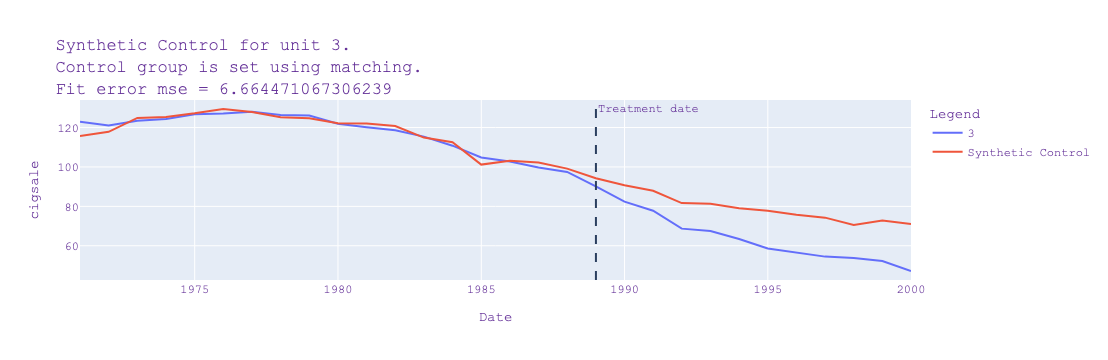

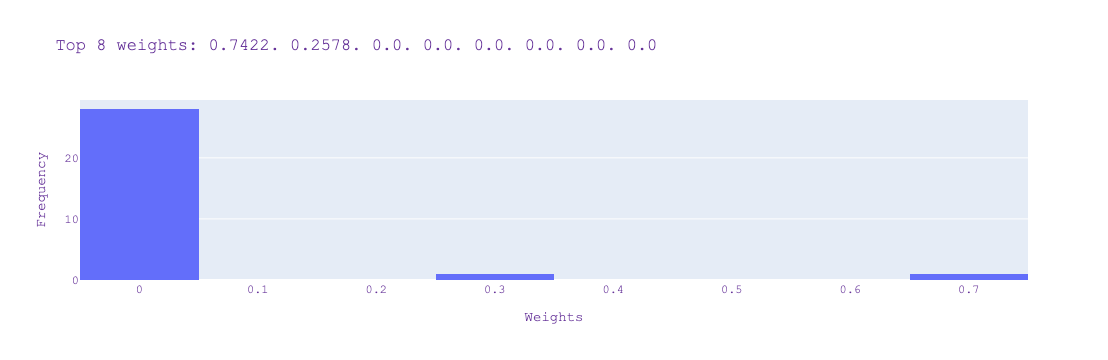

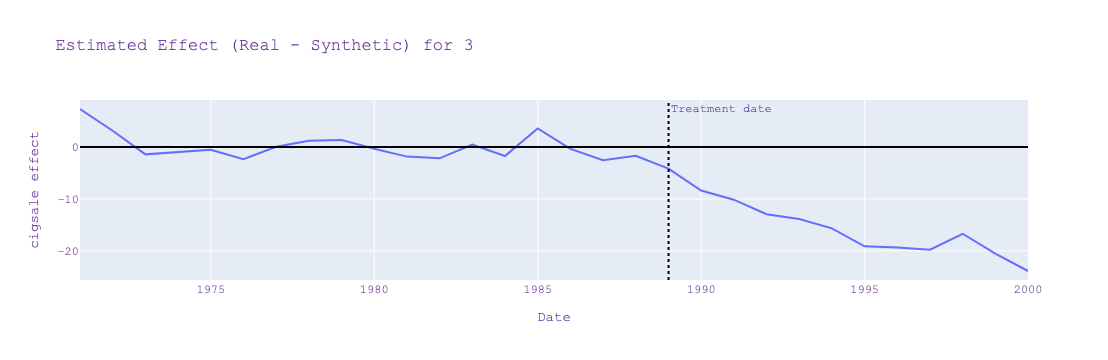

In [19]:
sc_feature.plot_results(feature="cigsale", top_weights_to_plot=8, with_effect=True)

## 7. Conformal Inference

Что делаем:
- считаем conformal residuals,
- получаем p-value и confidence intervals,
- строим объединённый dashboard.

Зачем:
- добавить статистическую неопределённость к оценке эффекта.


### 7.1 Residuals под нулевой гипотезой

Что делаем:
- считаем residuals при `H0: effect = 0`.

Зачем:
- это основа conformal p-value.


In [42]:
residuals = sc_feature.get_conformal_residuals(
    feature="cigsale",
    null_hypothesis=0.0,
    intervention_start=pd.Timestamp("1988-12-31"),
    window=13,
)
residuals.tail()

,date,y0,y0_est,residuals,post_intervention
25,1995-12-31,56.400002,74.069445,-17.669444,True
26,1996-12-31,54.500000,72.644320,-18.144320,True
27,1997-12-31,53.799999,68.848591,-15.048592,True
28,1998-12-31,52.299999,70.899819,-18.599820,True
29,1999-12-31,47.200001,68.917388,-21.717387,True


### 7.2 Conformal p-value для нулевого эффекта

Что делаем:
- оцениваем, насколько наблюдаемый эффект совместим с `H0`.

Зачем:
- получить формальную проверку статистической значимости.


In [43]:
p_value_h0_zero = sc_feature.get_conformal_p_value(
    feature="cigsale",
    null_hypothesis=0.0,
    window=13,
    q=1,
)
p_value_h0_zero

0.13333333333333333

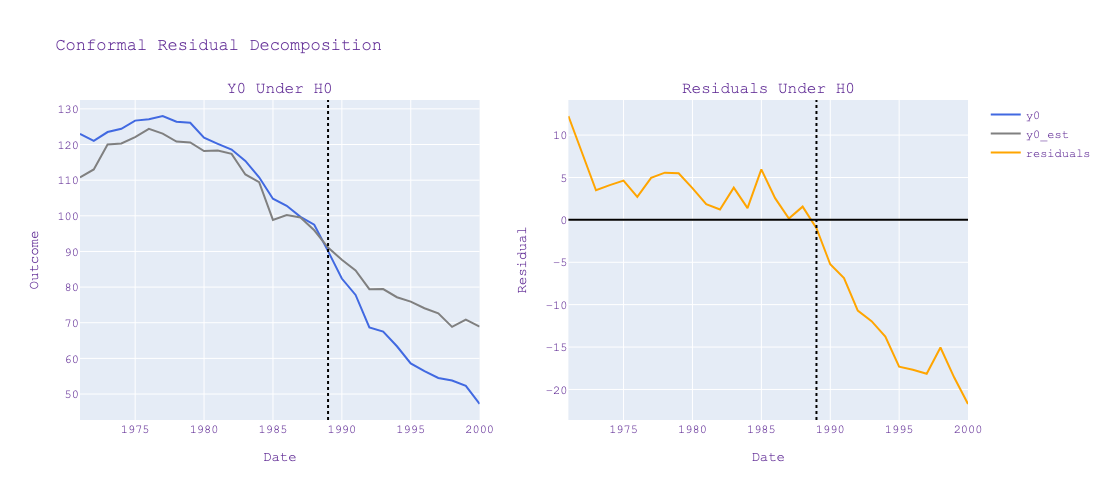

In [44]:
sc_feature.plot_conformal_residuals_decomposition(
    feature="cigsale",
    null_hypothesis=0.0,
    intervention_start=pd.Timestamp("1988-12-31"),
    window=13,
)

### 7.3 Сетка null-эффектов

Что делаем:
- задаём сетку кандидатов `H0` для построения CI.

Зачем:
- через инверсию p-value получить доверительный интервал.


In [91]:
null_grid = np.linspace(-80, 20, 401)  # шире
period = pd.Timestamp("1990-12-31")
start = pd.Timestamp("1988-12-31")
window = 12  # один и тот же везде

p_grid = sc_feature.get_conformal_p_value_grid_for_period(
    feature="cigsale",
    period=period,
    nulls=null_grid,
    intervention_start=start,
    q=1,
)
p_grid.head()

,1990-12-31
-80.00,0.052632
-79.75,0.052632
-79.50,0.052632
-79.25,0.052632
-79.00,0.052632


### 7.4 Conformal confidence interval

Что делаем:
- вычисляем CI по пост-treatment периодам.

Зачем:
- увидеть диапазон правдоподобных эффектов по времени.


In [92]:
ci = sc_feature.get_conformal_confidence_interval(
    feature="cigsale",
    nulls=null_grid,
    window=window,
    alpha=0.1,
    intervention_start=start,
    q=1,
)
ci

,90_ci_lower,90_ci_upper
1988-12-31,-11.25,6.25
1989-12-31,-15.50,-0.75
1990-12-31,-17.25,3.00
1991-12-31,-20.00,-5.75
1992-12-31,-20.75,-6.50
1993-12-31,-34.50,-8.50
1994-12-31,-36.25,-12.00
1995-12-31,-47.00,-12.25
1996-12-31,-45.50,-12.50
1997-12-31,-50.25,-9.50


### 7.5 Единый conformal dashboard

Что делаем:
- объединяем residuals, p-value grid и CI в одну визуализацию.

Зачем:
- быстрое end-to-end чтение качества и неопределённости эффекта.


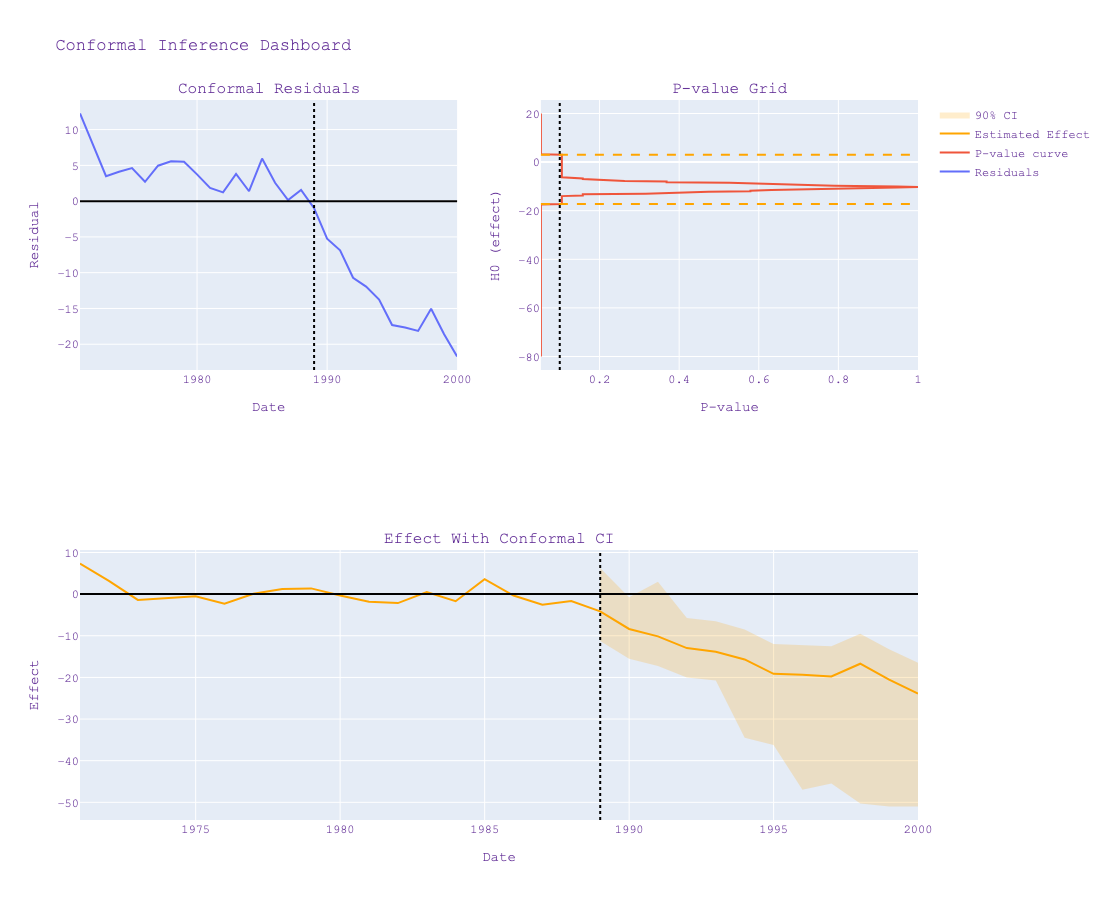

In [93]:
sc_feature.plot_conformal_dashboard(
    feature="cigsale",
    nulls=null_grid,
    window=window,
    period=period,
    intervention_start=start,
    alpha=0.1,
    q=1,
)

## 8. `Experiment`: пакетный запуск по нескольким treated-unit

Что делаем:
- демонстрируем split workflow (`fit_all -> evaluate`) и one-shot (`run_experiment`),
- показываем метрики по эксперименту.

Зачем:
- масштабировать анализ с одного юнита на набор treated-unit.


### 8.1 Настраиваем `Experiment`

Что делаем:
- формируем таблицу treated-unit и создаём объект эксперимента.

Зачем:
- перейти от single-unit анализа к пакетному сценарию.


In [18]:
# Для демонстрации Experiment используем 2 treated-unit (California + Arizona),
# чтобы статистика была осмысленной на маленьком примере.
# treatments_df = pd.DataFrame({
#     "state": [treated_state, "1", "10", "15"],
#     "treat_date": [treatment_date, treatment_date, treatment_date, treatment_date],
# })

treatments_df = pd.DataFrame({
    "state": ["228", "1"],
    "treat_date": [treatment_date, treatment_date],
})

experiment = Experiment(
    data=df,
    treatments_dataframe=treatments_df,
    unit_column="state",
    date_column="date",
    features=["cigsale"],
    treatment_date_column="treat_date",
    min_date="1970-01-01",
    max_date="2000-01-01",
    date_frequency="YE",
    aggregation_statistic="mean",
)

### 8.2 Split workflow: `fit_all`

Что делаем:
- обучаем Synthetic Control для каждого treated-unit отдельно.

Зачем:
- получить промежуточный контроль над этапом обучения.


Synth for treated_unit: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 61.52it/s]


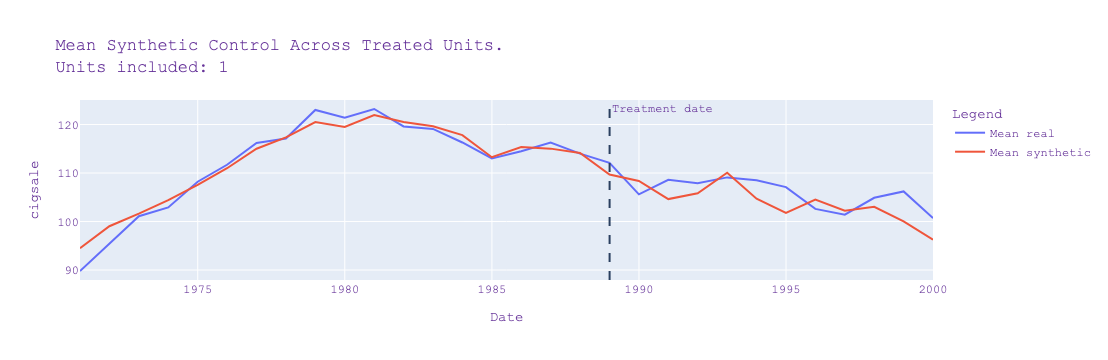

1

In [19]:
# Вариант 1: split workflow
fitted_units = experiment.fit_all(
    feature="cigsale",
    to_plot=False,
    control_group=all_controls,
    epochs=300,
    to_plot_aggregated = True,
    lr=0.05,
    continue_on_fit_error = True
)
len(fitted_units)

### 8.3 Split workflow: `evaluate`

Что делаем:
- агрегируем unit-level результаты, фильтруем по fit-quality и считаем тест.

Зачем:
- отделить этап инференса от этапа фита.


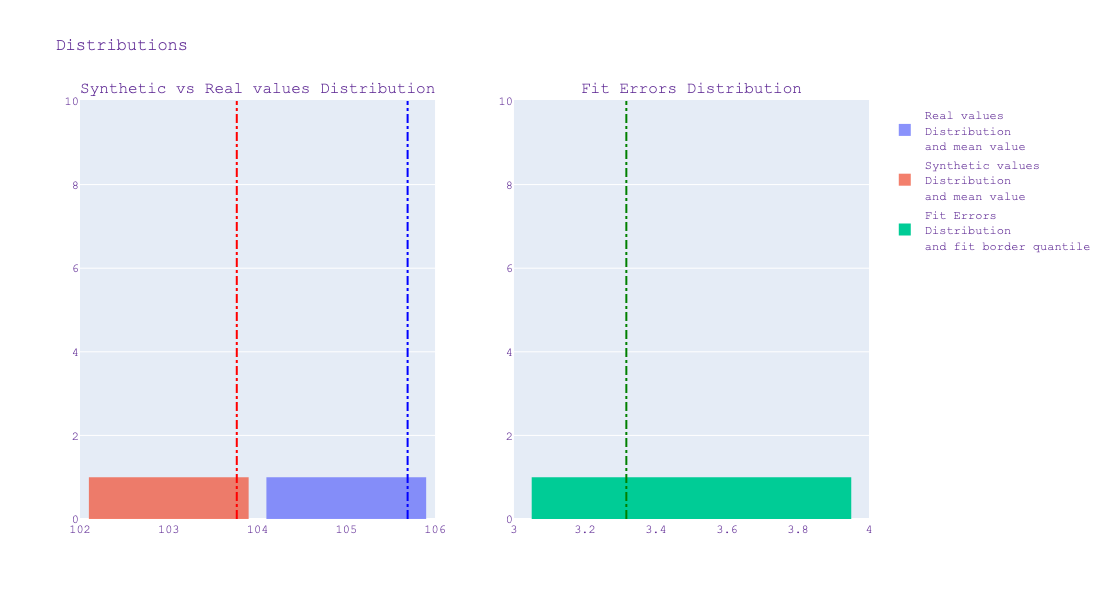

('independent_ttest', nan)

In [20]:
eval_result = experiment.evaluate(
    fitted_units=fitted_units,
    feature="cigsale",
    effect_evaluation_aggregation="mean_value",
    quantile_error_border=0.95,
    min_units_after_filter=1,
    min_units_for_inference=1,
    to_plot=True,
)

eval_result.test_name, eval_result.test_pvalue

### 8.4 One-shot workflow: `run_experiment`

Что делаем:
- запускаем весь pipeline одной командой.

Зачем:
- быстрый production-like запуск без ручной оркестрации.


Synth for treated_unit:   0%|                                                                                                                                  | 0/2 [00:00<?, ?it/s]2026-03-12 00:28:41.422 | INFO     | cib_advanced_experiments.experiment:fit_all:273 - 228 not in history DataFrame. Skip fitting it.


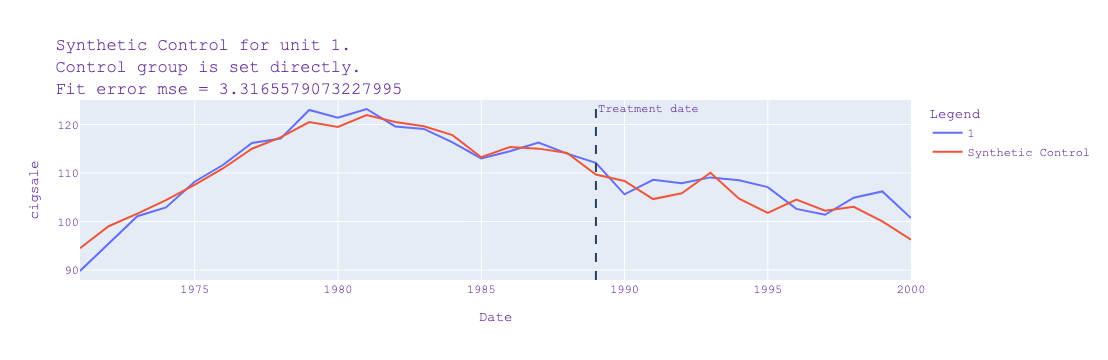

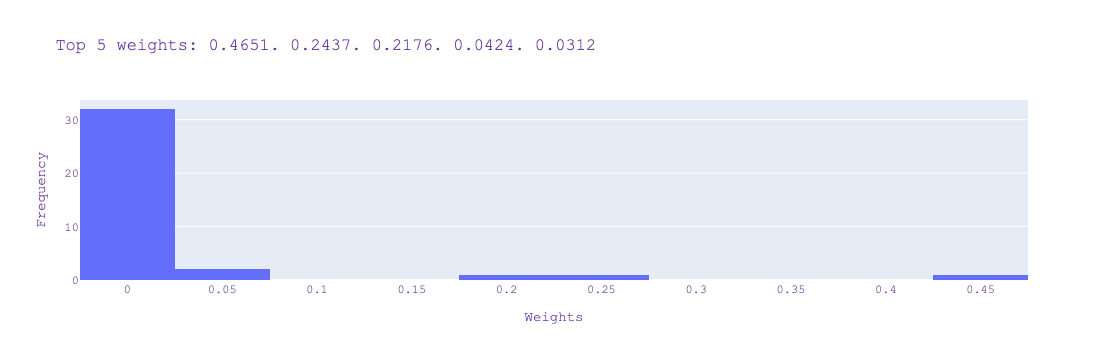

Synth for treated_unit: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 43.83it/s]


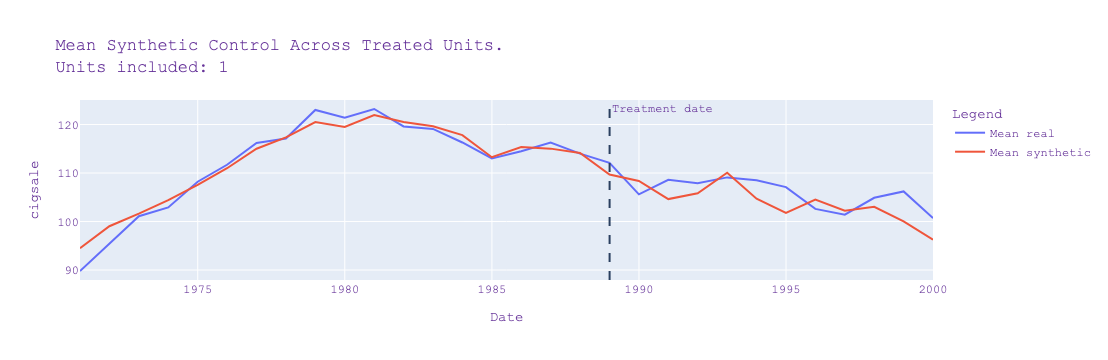

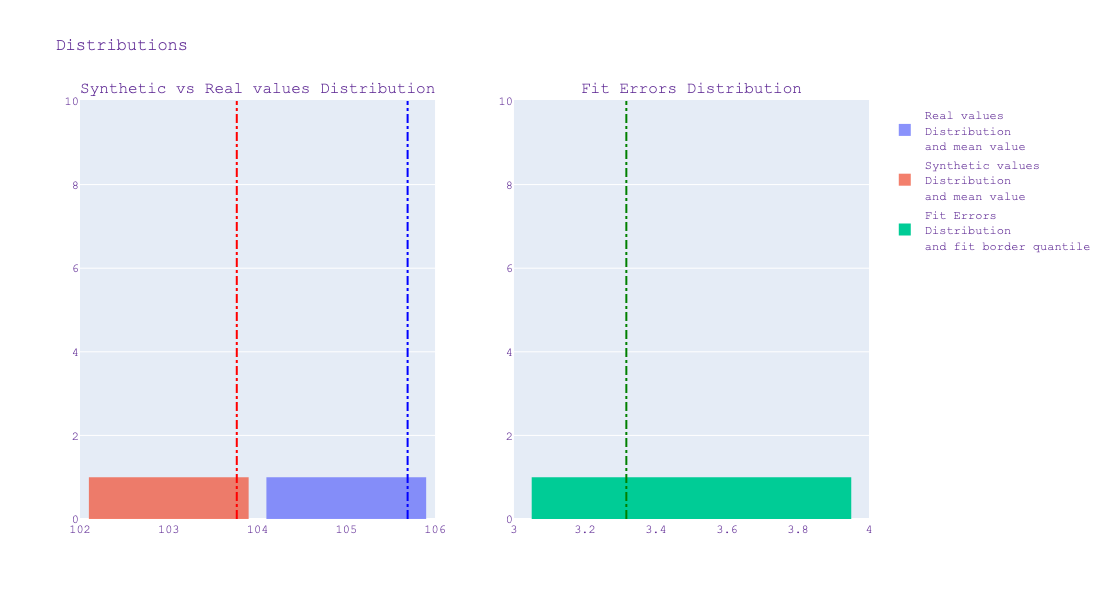

('permutation', 1.0)

In [21]:
# Вариант 2: full pipeline одной командой
run_result = experiment.run_experiment(
    feature="cigsale",
    to_plot=True,
    to_plot_individual=True,
    control_group=all_controls,
    epochs=300,
    lr=0.05,
    inference_method="permutation",
    permutation_iterations=500,
    min_units_after_filter=1,
    min_units_for_inference=1,
    to_plot_aggregated = True,
)

run_result.test_name, run_result.test_pvalue

### 8.5 Сводные метрики эксперимента

Что делаем:
- читаем итоговые метрики (`mean_real`, `mean_synthetic`, p-value и др.).

Зачем:
- получить компактный итог для отчёта и мониторинга.


In [22]:
experiment.get_metrics()

{'mean_synthetic': 103.76627075788579,
 'mean_real': 105.69090825861144,
 'expected_effect_in_percent': 1.855,
 'ttest_statistic': 1.9246375007256518,
 'ttest_pvalue': 1.0,
 'test_name': 'permutation',
 'included_units': 1,
 'excluded_units': 0}

## 9. Placebo Test для Synthetic Control

Что делаем:
- считаем placebo-эффекты (как если бы treatment был у других юнитов),
- сравниваем реальный эффект treated с placebo-распределением,
- интерпретируем placebo p-value.

Зачем:
- проверить, насколько эффект treated необычен относительно «случайных» интервенций.


### Шаг 1. Выбираем настройки Placebo

Что делаем:
- задаём способ агрегирования эффекта и фильтр по pre-treatment качеству (`pre_error_quantile`).

Зачем:
- сравнение с placebo становится более честным и устойчивым.


### Запускаем расчёт Placebo

Что делаем:
- считаем placebo по всем юнитам и строим итоговый объект `placebo_result`.

Зачем:
- получить и таблицу, и p-value, и данные для графиков.


In [23]:
placebo_result = sc_feature.get_placebo_result(
    feature="cigsale",
    effect_evaluation_aggregation="mean_value",
    pre_error_quantile=0.9,
    alternative="two-sided",
)

placebo_result.placebo_pvalue


0.10714285714285714

### Шаг 2. Проверяем таблицу по юнитам

Что делаем:
- смотрим `pre_treatment_mse` и агрегированный эффект по каждому юниту.

Зачем:
- видеть, какие placebo-фиты качественные и как они соотносятся с treated.


### Анализируем quality filter и эффекты

Что делаем:
- смотрим, какие юниты прошли фильтр по pre-treatment ошибке.

Зачем:
- убедиться, что сравнение treated с placebo корректное по качеству фита.


In [24]:
placebo_result.filtered_unit_level_summary.sort_values("pre_treatment_mse").head(12)


,treated_unit,is_actual_treated,pre_treatment_mse,effect
7,18,False,0.527885,11.146737
17,28,False,1.204271,0.805152
10,20,False,1.303492,5.764492
29,7,False,1.494152,-9.261056
20,31,False,2.342931,7.751695
30,9,False,2.603184,-0.942909
6,17,False,3.548821,5.659545
22,33,False,3.738816,-14.131039
25,38,False,3.836978,3.474658
15,26,False,3.838342,-1.816003


### Шаг 3. Интерпретируем `placebo_pvalue`

Правило чтения:
- чем меньше `placebo_pvalue`, тем менее типичен эффект treated относительно placebo.


### Краткая текстовая интерпретация

Что делаем:
- печатаем p-value и величину treated-эффекта.

Зачем:
- оставить в ноутбуке явный числовой итог анализа.


In [25]:
print(f"Placebo p-value (two-sided): {placebo_result.placebo_pvalue:.4f}")
print(f"Treated effect ({placebo_result.effect_evaluation_aggregation}): {placebo_result.treated_effect:.4f}")


Placebo p-value (two-sided): 0.1071
Treated effect (mean_value): -16.4011


### Шаг 4. График placebo gap paths

Что видим:
- серые линии — placebo,
- выделенная линия — реальный treated-unit.

Зачем:
- визуально оценить, выбивается ли treated-траектория.


### Визуальная проверка траекторий

Что делаем:
- строим график placebo gaps по времени.

Зачем:
- увидеть динамику эффекта treated относительно placebo-фона.


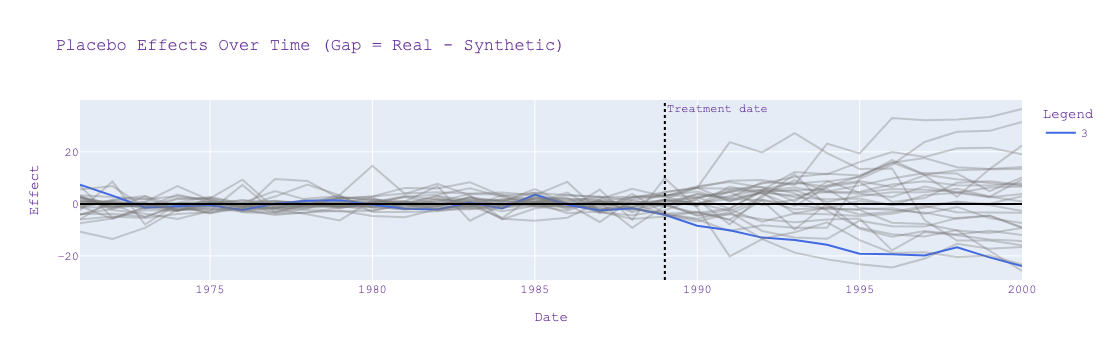

In [26]:
sc_feature.plot_placebo_effects(
    feature="cigsale",
    pre_error_quantile=0.9,
)


### Шаг 5. Распределение placebo-эффектов

Что видим:
- гистограмму placebo-эффектов и маркер treated-эффекта.

Зачем:
- получить интуитивную визуальную проверку результата p-value.


### Финальная визуальная проверка распределения

Что делаем:
- строим гистограмму placebo-эффектов с treated-маркером.

Зачем:
- завершить placebo-анализ на интуитивно читаемой картинке.


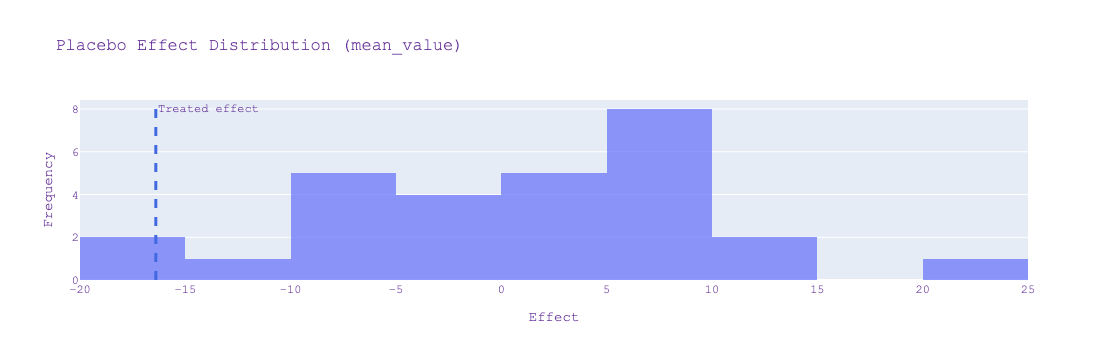

In [27]:
sc_feature.plot_placebo_distribution(
    feature="cigsale",
    effect_evaluation_aggregation="mean_value",
    pre_error_quantile=0.9,
    alternative="two-sided",
)


## 10. Difference-in-Differences (DiD)

В этом блоке повторяем классическую DiD-логику из каузального пайплайна:
- формируем индикаторы treated/post,
- считаем 2x2 DiD-оценку,
- проверяем графики (2x2 и тренды),
- интерпретируем коэффициент и p-value.


### Шаг 1. Формируем данные под DiD

Что делаем:
- `treated = 1` для California, `0` для остальных;
- `post = 1` после даты интервенции, `0` до неё.

Зачем:
- это минимально необходимая структура для оценки классического DiD.


In [28]:
did_data = df.copy()
did_data["treated"] = (did_data["state"] == treated_state).astype(int)
did_data["post"] = (did_data["date"] >= treatment_date).astype(int)

did_data[["treated", "post"]].value_counts().sort_index()


treated  post
0        0       722
         1       456
1        0        19
         1        12
Name: count, dtype: int64

### Шаг 2. Оцениваем DiD

Что делаем:
- запускаем `DifferenceInDifferences` и получаем оценку эффекта treatment.

Зачем:
- получить интерпретируемую causal-оценку в 2x2 постановке.


In [29]:
did = DifferenceInDifferences(
    data=did_data,
    outcome_column="cigsale",
    treatment_column="treated",
    post_column="post",
)

did_result = did.fit(alpha=0.05)
did_result


DifferenceInDifferencesResult(estimate=-27.34911108193087, std_error=10.9113074868964, t_statistic=-2.5064925642298093, pvalue=0.012324451021742622, ci_lower=-48.7563829861773, ci_upper=-5.9418391776844395, alpha=0.05, n_obs=1209, group_means=     group  post_period  mean_outcome
0  control            0    130.569529
1  control            1    102.058114
2  treated            0    116.210526
3  treated            1     60.350000, counterfactual_treated_post=87.69911114550915)

### Шаг 3. Читаем итоговые числа

Что важно:
- `estimate` — DiD-эффект,
- `pvalue` — статистическая значимость,
- `ci_lower/ci_upper` — доверительный интервал эффекта.


In [30]:
print(f"DiD estimate: {did_result.estimate:.4f}")
print(f"Std. error: {did_result.std_error:.4f}")
print(f"P-value: {did_result.pvalue:.6f}")
print(f"95% CI: [{did_result.ci_lower:.4f}, {did_result.ci_upper:.4f}]")


DiD estimate: -27.3491
Std. error: 10.9113
P-value: 0.012324
95% CI: [-48.7564, -5.9418]


### Шаг 4. Визуализация 2x2 DiD

Что видим:
- средние по группам (treated/control) до и после интервенции,
- контрфакт treated-post без treatment.

Зачем:
- быстро проверить геометрию DiD-оценки на графике.


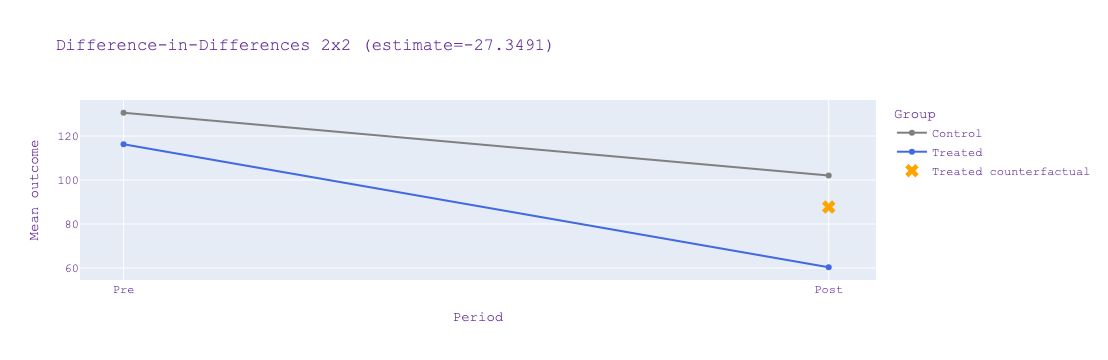

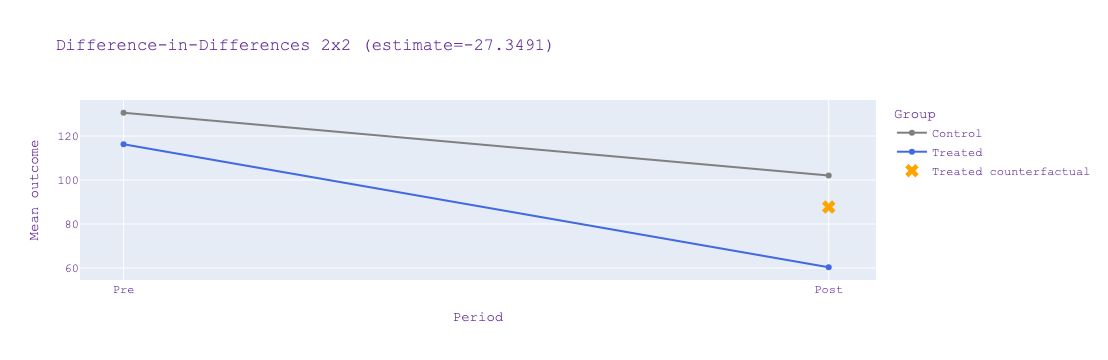

In [31]:
did.plot_2x2()


### Шаг 5. Визуальная проверка parallel trends

Что делаем:
- строим динамику средних treated/control по времени.

Зачем:
- проверить, насколько разумно предположение о параллельных трендах.


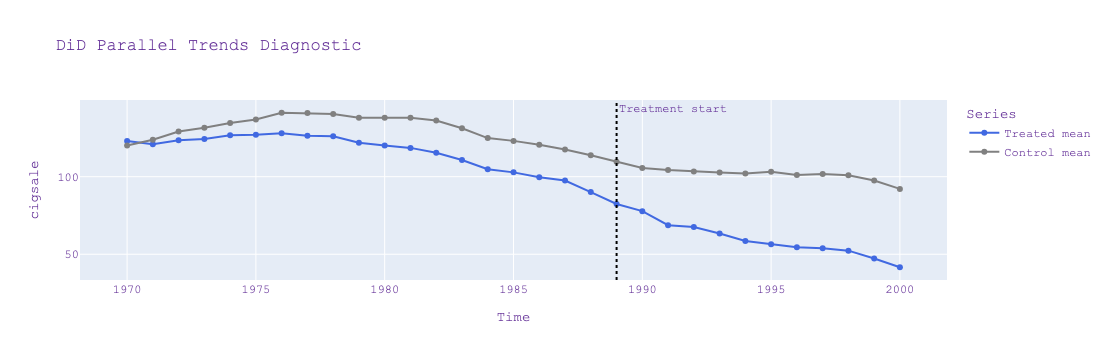

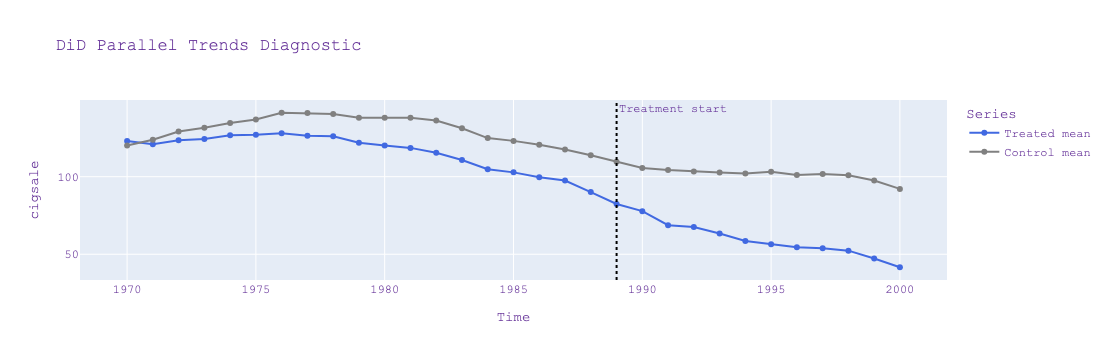

In [32]:
did.plot_parallel_trends(
    time_column="date",
    treatment_start=treatment_date,
    pre_period_only=False,
)
